# Flow óptico e transporte de máscara em VFSS

**Pergunta:** a estimativa de movimento entre frames é boa o bastante, em VFSS, para transportar a
máscara prevista de um frame para outro? A técnica é inspirada no
[DTC-TRUS](https://github.com/DYDevelop/DTC-TRUS), que usa esse transporte numa loss de consistência
temporal.

## Notação e pipeline

Dado um par de frames $(I_{t-1}, I_t)$, onde o "$t-1$" é, de modo geral, o frame $t-T$:

1. Um modelo supervisionado já treinado prevê $P_{t-1}$ e $P_t$.
2. Calcula-se o flow $F_{t-1\to t}$.
3. A máscara é transportada: $\tilde P_{t-1\to t} = W(P_{t-1}, F_{t-1\to t})$.
4. O erro de oclusão/movimento vira um mapa de confiança:
   $M_{noc} = \exp(-\alpha\,|I_t - W(I_{t-1}, F_{t-1\to t})|)$.

## As duas convenções de warp (`WARP_CONVENTION`)

O flow $F_{a\to b}(p)$ diz que o pixel $p$ do frame $a$ vai para $p + F(p)$ no frame $b$. Já o
`grid_sample` percorre cada pixel $x$ do frame **de destino** e pergunta de onde buscar o valor.

- **`backward`**: amostra em $x + F_{t\to t-1}(x)$. O flow está definido no grid de $t$ e responde
  diretamente de onde $x$ veio.
- **`dtc_trus`**: amostra em $x - F_{t-1\to t}(x)$. A origem verdadeira $p$ satisfaz $p = x - F(p)$,
  mas $p$ é desconhecido; a fórmula troca $F(p)$ por $F(x)$, isto é, lê a velocidade no destino.

Em movimento localmente uniforme as duas coincidem. Exemplo em 1D: uma estrutura ocupa $[10, 20]$ em
$t-1$, anda $+8$ e ocupa $[18, 28]$ em $t$, com fundo parado.

| Convenção | Máscara transportada | Erro |
|---|---|---|
| Correto | $[18, 28]$ | nenhum |
| `dtc_trus` | $[18, 20]$ | perde a frente da estrutura (o flow em $x=24$ ainda é 0) |
| `backward` | $[10, 28]$ | deixa rastro em $[10, 18)$ (o fundo em $t$ tem flow 0 e lê a estrutura antiga) |

Nenhuma é exata onde um pixel aparece ou desaparece, porque ali não existe valor correto para buscar.
O flow real é suave e atenua esses extremos. O $M_{noc}$ existe para sinalizar esses pixels.

## O que difere do DTC-TRUS

- **`PHOTO_NORM` é novo.** O DTC-TRUS usa `A.Normalize()` (constantes ImageNet, ganho fixo entre
  frames). Aqui, a entrada do modelo continua com o min-max por frame com que ele foi treinado, mas
  flow e $M_{noc}$ usam uma imagem separada. O padrão `raw` (`pixel/255`) mantém o ganho fixo.
- **Faixa de intensidade do flow.** O DTC-TRUS passa ao flow tensores já normalizados com ImageNet, e
  o pré-processamento dele faz *clip* em $[0,1]$. Só cerca de `pixel/255` entre 0,46 e 0,68 chega sem
  saturar. Este notebook não reproduz esse corte.
- **Pares.** O DTC-TRUS só compara frames adjacentes (`frame_gap` não é usado), então $T>1$ vai além
  do que a referência testou.
- **$\alpha$.** O padrão do DTC-TRUS é $\exp(-1{,}0\,|\sum_c(\cdot)|)$ sobre imagens ImageNet. Em cinza
  repetido e escala $[0,1]$, isso equivale a $\alpha = \sum_c 1/\sigma_c \approx 13{,}27$, que é o
  padrão aqui. $\alpha=1$ é a forma literal da fórmula acima.

## Ressalvas de leitura

- **A máscara é de vértebras (C2 a C8, `binary_all`), não do bolo.** Com $T=1$ elas se movem pouco, e o
  baseline sem transporte já concorda muito com $P_t$. Valores maiores de $T$ testam melhor o transporte.
  O bolo atua como perturbação: passa sobre as vértebras e muda o brilho local.
- `PHOTO_NORM` tende a mudar pouco neste dataset. Numa amostra de 60 vídeos (10 frames cada), o mínimo
  foi 0 em todos os frames, por causa da colimação preta. O máximo foi 255 em todos os frames amostrados
  de 73% dos vídeos e variou até 21 níveis dentro de um vídeo.
- Dice$(P_t, \tilde P)$ mede concordância com o modelo, não acerto. Só a anotação mede acerto, e há
  apenas 118 pares anotados consecutivos no dataset.
- Métricas na imagem inteira favorecem flow zero, porque o fundo é majoritariamente parado.

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

## 1. Parâmetros

`ARCH` e `FOLD` escolhem o modelo entre os 25 runs da validação cruzada E1. Os demais controlam o
flow. Depois de alterar, execute novamente a partir da célula de carga (seção 2) ou do pipeline
(seção 5), conforme o caso.

In [2]:
import os
import sys
from pathlib import Path

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src").is_dir())
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F_nn
from IPython.display import display
from matplotlib.patches import Patch
from omegaconf import OmegaConf
from torchvision.models.optical_flow import (
    Raft_Large_Weights,
    Raft_Small_Weights,
    raft_large,
    raft_small,
)
from torchvision.utils import flow_to_image

from src.utils import get_obj_from_str, instantiate_from_config

try:
    import ipywidgets as widgets
    HAS_WIDGETS = True
except ImportError:
    widgets = None
    HAS_WIDGETS = False
    print("ipywidgets indisponível: as células interativas renderizam só os valores padrão.")

# Modelo
ARCH = "deeplabv3plus"                 # unet | unetplusplus | fpn | deeplabv3plus | swinunet_tiny
FOLD = 0                      # 0..4
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Par de frames
T = 1                         # distância entre os frames: o segundo frame é t - T
RANDOM_SEED = 0               # sorteio do botão "par aleatório"

# Flow
FLOW_METHOD = "farneback"     # farneback | dis | raft_small | raft_large
FLOW_PREPROCESS = "dtc_rgb"   # dtc_rgb | dtc_ultrasound | vfss | none (só métodos clássicos)
PHOTO_NORM = "raw"            # raw | pair | frame (imagem usada no flow e no M_noc)
WARP_CONVENTION = "dtc_trus"  # dtc_trus | backward

FARNEBACK_PARAMS = dict(      # padrão do DTC-TRUS
    pyr_scale=0.5, levels=3, winsize=15, iterations=3, poly_n=5, poly_sigma=1.2, flags=0,
)
FARNEBACK_MEDIAN_KSIZE = 3    # mediana aplicada em u e v, como no DTC-TRUS (0 desliga)
DIS_PRESET = "medium"         # ultrafast | fast | medium
RAFT_UPDATES = 12             # refinamentos do RAFT (padrão do torchvision)

# Erro de movimento e visualização
IMAGENET_STD = (0.229, 0.224, 0.225)
ALPHA_DTC_TRUS = sum(1.0 / s for s in IMAGENET_STD)   # exp(-1.0*|soma nos canais|) sobre ImageNet
ALPHA = ALPHA_DTC_TRUS        # 1.0 é a forma literal exp(-|I_t - W|)
OPACITY = 0.5
MASK_THRESH = 0.5

SPLITS = ["train", "validation", "test"]
FLOW_METHODS = ["farneback", "dis", "raft_small", "raft_large"]

## 2. Modelo e dados

O DataModule vem do `config.yaml` do próprio run, com `cache_splits = []` para não carregar os splits
em RAM. No config do E1, `test` é o fold retido daquele modelo e o teste INCA não é alcançável.

In [3]:
def find_run_dir(arch, fold, seed):
    '''Diretório do run E1 da arquitetura/fold/seed (o mais recente, se houver mais de um).'''
    pattern = f"e1-cv-{arch}-f{fold}-s{seed}"
    run_dirs = sorted((ROOT / "logs/e1-cv/runs" / pattern).glob("*/"))
    if not run_dirs:
        raise FileNotFoundError(f"Nenhum run encontrado para {pattern}")
    return run_dirs[-1]


def load_lit_module(run_dir, device):
    '''Reconstrói o módulo a partir do config.yaml do run e carrega o melhor checkpoint.'''
    cfg = OmegaConf.load(run_dir / "config.yaml")
    # Os pesos vêm do checkpoint; não precisa baixar/ler os pré-treinados.
    for key in ("encoder_weights", "pretrain_ckpt"):
        if key in cfg.model.params:
            cfg.model.params[key] = None
    cls = get_obj_from_str(cfg.lit_module.target)
    module = cls(model_cfg=cfg.model, optimizer_cfg=cfg.optimizer,
                 lr_scheduler_cfg=cfg.get("lr_scheduler"), **dict(cfg.lit_module.params))
    ckpt_path = sorted((run_dir / "checkpoints").glob("best-*.ckpt"))[-1]
    state = torch.load(ckpt_path, map_location="cpu", weights_only=False)["state_dict"]
    module.load_state_dict(state)
    return cfg, module.to(device).eval(), ckpt_path


run_dir = find_run_dir(ARCH, FOLD, SEED)
run_cfg, model, ckpt_path = load_lit_module(run_dir, DEVICE)

data_cfg = OmegaConf.load(run_dir / "config.yaml").data
data_cfg.params.cache_splits = []
data_module = instantiate_from_config(data_cfg)
data_module.setup("test")
datasets = {split: data_module.datasets[split] for split in SPLITS}

print(f"Modelo: {ckpt_path.relative_to(ROOT)}")
for split, ds in datasets.items():
    print(f"{split:<11} {ds.video_frame_df.video_id.nunique():>3} vídeos, "
          f"{ds.video_frame_df.paciente_id.nunique():>3} pacientes, {len(ds):>4} frames anotados")

/home/caioseda/miniconda3/envs/vfss/lib/python3.12/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


Modelo: logs/e1-cv/runs/e1-cv-deeplabv3plus-f0-s42/2026-10-30-15-09-13/checkpoints/best-epoch=57-step=3499.ckpt
train       123 vídeos,  64 pacientes,  491 frames anotados
validation   26 vídeos,  11 pacientes,  110 frames anotados
test         27 vídeos,  16 pacientes,  121 frames anotados


## 3. Funções do pipeline

Há **dois caminhos de imagem**. A entrada do modelo é a mesma do treino (min-max por frame, $[-1,1]$,
resize). A imagem para flow e $M_{noc}$ fica em $[0,1]$, segundo `PHOTO_NORM`:

- `raw`: `pixel/255`, sem min-max.
- `pair`: mínimo e máximo compartilhados pelos dois frames.
- `frame`: min-max por frame, para comparar com o que o modelo vê.

`FLOW_PREPROCESS` só se aplica aos métodos clássicos, depois de `PHOTO_NORM`:

| Opção | Bilateral (d/σcor/σespaço) | CLAHE | Gauss 3×3 |
|---|---|---|---|
| `dtc_rgb` | 5/50/50 | 2,0 em 8×8 | σ 0,3 |
| `dtc_ultrasound` | 9/75/75 | 2,0 em 8×8 | σ 0,5 |
| `vfss` | 5/50/50 | não | σ 0,3 |
| `none` | não | não | não |

O `vfss` omite o CLAHE porque o mapeamento dele é calculado por frame e por região: a entrada do bolo
muda o histograma local e altera o brilho do tecido vizinho, o que imita movimento.

In [4]:
FLOW_PREPROCESS_CONFIGS = {
    "dtc_rgb": dict(bilateral=(5, 50, 50), clahe=True, gauss_sigma=0.3),
    "dtc_ultrasound": dict(bilateral=(9, 75, 75), clahe=True, gauss_sigma=0.5),
    "vfss": dict(bilateral=(5, 50, 50), clahe=False, gauss_sigma=0.3),
    "none": None,
}
DIS_PRESETS = {
    "ultrafast": cv2.DISOPTICAL_FLOW_PRESET_ULTRAFAST,
    "fast": cv2.DISOPTICAL_FLOW_PRESET_FAST,
    "medium": cv2.DISOPTICAL_FLOW_PRESET_MEDIUM,
}
RAFT_BUILDERS = {
    "raft_small": (raft_small, Raft_Small_Weights.DEFAULT),
    "raft_large": (raft_large, Raft_Large_Weights.DEFAULT),
}
_raft_models = {}


def model_input(ds, video_id, frame_id):
    '''Tensor [C,H,W] exatamente como o modelo viu no treino.'''
    raw = ds._load_image(video_id, frame_id, color="greyscale")
    if ds.repeat_channels:
        raw = raw.repeat(3, 1, 1)
    return ds._preprocess_image(raw)


def _rescale(x, low, high):
    return (x - low) / (high - low + 1e-8)


def photo_pair(ds, video_id, frame_a, frame_b, norm):
    '''Par de imagens [1,1,H,W] em [0,1] para flow e M_noc, normalizadas segundo PHOTO_NORM.'''
    a = ds._load_image(video_id, frame_a, color="greyscale").float() / 255.0
    b = ds._load_image(video_id, frame_b, color="greyscale").float() / 255.0
    if norm == "frame":
        a, b = _rescale(a, a.min(), a.max()), _rescale(b, b.min(), b.max())
    elif norm == "pair":
        low, high = min(a.min(), b.min()), max(a.max(), b.max())
        a, b = _rescale(a, low, high), _rescale(b, low, high)
    elif norm != "raw":
        raise ValueError(f"PHOTO_NORM desconhecido: {norm}")
    a = ds.image_transform(a).clamp(0.0, 1.0)
    b = ds.image_transform(b).clamp(0.0, 1.0)
    return a[None], b[None]


@torch.no_grad()
def predict_fg(inputs):
    '''Probabilidade da classe FG, [1,1,H,W], para uma entrada [C,H,W] do modelo.'''
    logits = model(inputs[None].to(DEVICE))
    return torch.softmax(logits, dim=1)[:, 1:2].cpu()


def preprocess_for_flow(image, name):
    '''Converte [H,W] em [0,1] para uint8 e aplica o pré-processamento dos métodos clássicos.'''
    if name not in FLOW_PREPROCESS_CONFIGS:
        raise ValueError(f"FLOW_PREPROCESS desconhecido: {name}")
    out = (np.clip(image, 0.0, 1.0) * 255).astype(np.uint8)
    config = FLOW_PREPROCESS_CONFIGS[name]
    if config is None:
        return out
    d, sigma_color, sigma_space = config["bilateral"]
    out = cv2.bilateralFilter(out, d=d, sigmaColor=sigma_color, sigmaSpace=sigma_space)
    if config["clahe"]:
        out = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(out)
    return cv2.GaussianBlur(out, (3, 3), config["gauss_sigma"])


def _raft_flow(src, dst, method):
    if method not in _raft_models:
        builder, weights = RAFT_BUILDERS[method]
        _raft_models[method] = builder(weights=weights, progress=False).to(DEVICE).eval()
    height, width = src.shape[-2:]
    if height % 8 or width % 8:
        raise ValueError(f"RAFT exige lados múltiplos de 8; recebeu {height}x{width}")
    a = (src * 2.0 - 1.0).repeat(1, 3, 1, 1).to(DEVICE)
    b = (dst * 2.0 - 1.0).repeat(1, 3, 1, 1).to(DEVICE)
    with torch.no_grad():
        return _raft_models[method](a, b, num_flow_updates=RAFT_UPDATES)[-1].cpu()


def compute_flow(src, dst, method, preprocess):
    '''Flow F_{src->dst} em pixels, [1,2,H,W], para imagens [1,1,H,W] em [0,1].'''
    if method in RAFT_BUILDERS:
        return _raft_flow(src, dst, method)
    a = preprocess_for_flow(src[0, 0].numpy(), preprocess)
    b = preprocess_for_flow(dst[0, 0].numpy(), preprocess)
    if method == "farneback":
        flow = cv2.calcOpticalFlowFarneback(a, b, None, **FARNEBACK_PARAMS)
        if FARNEBACK_MEDIAN_KSIZE:
            flow = np.stack([cv2.medianBlur(flow[..., i], FARNEBACK_MEDIAN_KSIZE) for i in range(2)], axis=-1)
    elif method == "dis":
        flow = cv2.DISOpticalFlow_create(DIS_PRESETS[DIS_PRESET]).calc(a, b, None)
    else:
        raise ValueError(f"FLOW_METHOD desconhecido: {method}")
    return torch.from_numpy(flow).permute(2, 0, 1)[None].float()


def warp(x, flow, sign):
    '''Amostra x [B,C,H,W] em base + sign*flow (flow em pixels, [B,2,H,W]).'''
    batch, _, height, width = x.shape
    ys, xs = torch.meshgrid(torch.linspace(-1, 1, height), torch.linspace(-1, 1, width), indexing="ij")
    base = torch.stack((xs, ys), dim=-1)[None].repeat(batch, 1, 1, 1).to(x)
    dx = 2.0 * flow[:, 0] / max(width - 1, 1)
    dy = 2.0 * flow[:, 1] / max(height - 1, 1)
    grid = base + sign * torch.stack((dx, dy), dim=-1).to(x)
    return F_nn.grid_sample(x, grid, mode="bilinear", padding_mode="border", align_corners=True)


def motion_error(I_t, I_warped, alpha):
    '''M_noc = exp(-alpha*|I_t - W(I_{t-1})|), próximo de 1 onde o warp explica a imagem.'''
    return np.exp(-alpha * np.abs(I_t - I_warped))


def dice(a, b):
    '''Dice entre máscaras booleanas; NaN se ambas forem vazias.'''
    denominator = a.sum() + b.sum()
    return 2.0 * (a & b).sum() / denominator if denominator else float("nan")


def predict_pair(selection):
    '''Previsões P_{t-1} e P_t do par selecionado.'''
    ds = datasets[selection["split"]]
    video_id = selection["video_id"]
    return {
        "P_prev": predict_fg(model_input(ds, video_id, selection["frame_prev"])),
        "P_t": predict_fg(model_input(ds, video_id, selection["frame_t"])),
    }


def transport_pair(selection, preds, method, preprocess, norm, convention, alpha):
    '''Calcula flow, warp da imagem e da máscara e M_noc. Devolve arrays [H,W] (flow: [2,H,W]).'''
    ds = datasets[selection["split"]]
    I_prev, I_t = photo_pair(ds, selection["video_id"], selection["frame_prev"], selection["frame_t"], norm)
    forward = compute_flow(I_prev, I_t, method, preprocess)
    if convention == "dtc_trus":
        flow_used, sign, flow_name = forward, -1.0, "F_{t-1→t}"
    elif convention == "backward":
        flow_used, sign, flow_name = compute_flow(I_t, I_prev, method, preprocess), 1.0, "F_{t→t-1}"
    else:
        raise ValueError(f"WARP_CONVENTION desconhecida: {convention}")
    I_warped = warp(I_prev, flow_used, sign)
    P_tilde = warp(preds["P_prev"], flow_used, sign)
    result = {
        "I_prev": I_prev[0, 0].numpy(), "I_t": I_t[0, 0].numpy(), "I_warped": I_warped[0, 0].numpy(),
        "P_prev": preds["P_prev"][0, 0].numpy(), "P_t": preds["P_t"][0, 0].numpy(),
        "P_tilde": P_tilde[0, 0].numpy(), "F_forward": forward[0].numpy(), "F_used": flow_used[0].numpy(),
        "flow_name": flow_name, "alpha": alpha, "selection": dict(selection),
        "config": dict(method=method, preprocess=preprocess, norm=norm, convention=convention),
    }
    result["M_noc"] = motion_error(result["I_t"], result["I_warped"], alpha)
    return result


def magnitude_table(result, thresh):
    '''p50, p95 e máximo de |F_{t-1->t}| na imagem inteira e dentro de P_{t-1} binarizada.'''
    magnitude = np.linalg.norm(result["F_forward"], axis=0)
    regions = {"imagem inteira": magnitude, "dentro de P_{t-1}": magnitude[result["P_prev"] >= thresh]}
    rows = [
        {"região": name, "pixels": values.size,
         "p50 (px)": np.percentile(values, 50) if values.size else float("nan"),
         "p95 (px)": np.percentile(values, 95) if values.size else float("nan"),
         "máx (px)": values.max() if values.size else float("nan")}
        for name, values in regions.items()
    ]
    return pd.DataFrame(rows).set_index("região")


def pair_metrics(result, thresh, gt=None):
    '''Métricas do par na imagem inteira. `gt` é a anotação booleana do frame t, se existir.'''
    P_t, P_prev, P_tilde = result["P_t"] >= thresh, result["P_prev"] >= thresh, result["P_tilde"] >= thresh
    # Como no DTC-TRUS: a máscara transportada é binarizada e a do frame t continua contínua.
    temporal = 1.0 - np.mean(result["M_noc"] * (1.0 - np.abs(result["P_t"] - P_tilde.astype(float))))
    row = {
        "Dice(P_t, P̃)": dice(P_t, P_tilde),
        "Dice(P_t, P_{t-1}) sem transporte": dice(P_t, P_prev),
        "|I_t - W| médio": np.abs(result["I_t"] - result["I_warped"]).mean(),
        "|I_t - I_{t-1}| médio": np.abs(result["I_t"] - result["I_prev"]).mean(),
        "L_temporal DTC-TRUS": temporal,
    }
    if gt is not None:
        row["Dice(GT, P̃)"] = dice(gt, P_tilde)
        row["Dice(GT, P_t)"] = dice(gt, P_t)
    return row

## 4. Explorador do dataset

Escolha o split, o vídeo e o frame $t$. Por padrão, o segundo frame é $t-T$. No modo manual, um slider
próprio escolhe o segundo frame. Se $t-T$ não existir, o explorador avisa e passa para o modo manual.
O botão de par aleatório sorteia $t$ em $[1+T, N]$ e volta ao modo automático.

- ★ marca os frames anotados.
- Em `train`, o modelo viu os frames anotados. Em `validation`, esses frames guiaram a escolha do
  checkpoint. Só `test` (o fold retido) não influenciou o modelo.

`SELECTION` é atualizado a cada mudança. **Depois de escolher, execute a seção 5.**

In [5]:
def default_selection(split, distance):
    '''Primeiro frame anotado do split com t - T válido, para "Run All" funcionar sem clique.'''
    df = datasets[split].video_frame_df.sort_values(["video_id", "frame_id"])
    row = df[df.frame_id > distance].iloc[0]
    return {"split": split, "video_id": int(row.video_id),
            "frame_prev": int(row.frame_id) - distance, "frame_t": int(row.frame_id)}


def annotated_frames(split, video_id):
    df = datasets[split].video_frame_df
    return set(df[df.video_id == video_id].frame_id.astype(int))


def video_options(split):
    df = datasets[split].video_frame_df
    grouped = df.groupby("video_id").agg(paciente=("paciente_id", "first"), anotados=("frame_id", "size"))
    return [(f"v{vid} · paciente {row.paciente} · {row.anotados} anotados", int(vid))
            for vid, row in grouped.sort_index().iterrows()]


def preview_png(split, video_id, frame_id):
    '''PNG do frame em 256x256, sem min-max, para o explorador.'''
    ds = datasets[split]
    image = ds.image_transform(ds._load_image(video_id, frame_id, color="greyscale").float() / 255.0)
    array = (image[0].clamp(0.0, 1.0).numpy() * 255).astype(np.uint8)
    return cv2.imencode(".png", array)[1].tobytes()


class FrameExplorer:
    '''Widgets de escolha do par. Mantém o dicionário SELECTION sempre atualizado.'''

    def __init__(self, selection, distance, seed):
        self.selection = selection
        self.rng = np.random.default_rng(seed)
        self._busy = True
        split, video_id = selection["split"], selection["video_id"]
        self.split = widgets.Dropdown(options=SPLITS, value=split, description="Split")
        self.video = widgets.Dropdown(options=video_options(split), value=video_id, description="Vídeo",
                                      layout=widgets.Layout(width="420px"))
        self.play = widgets.Play(interval=200, min=1, max=2, value=1, description="Reproduzir")
        self.t = widgets.IntSlider(min=1, max=2, value=1, description="Frame t",
                                   layout=widgets.Layout(width="640px"))
        widgets.jslink((self.play, "value"), (self.t, "value"))
        self.T = widgets.IntSlider(min=1, max=60, value=distance, description="T")
        self.mode = widgets.ToggleButtons(options=[("Automático (t−T)", "auto"), ("Manual", "manual")],
                                          value="auto", description="2º frame")
        self.prev = widgets.IntSlider(min=1, max=2, value=1, description="Segundo frame", disabled=True,
                                      style={"description_width": "initial"},
                                      layout=widgets.Layout(width="640px"))
        self.random = widgets.Button(description="Par aleatório", icon="random")
        self.status = widgets.HTML()
        self.label_prev, self.label_t = widgets.HTML(), widgets.HTML()
        self.image_prev = widgets.Image(format="png", width=384, height=384)
        self.image_t = widgets.Image(format="png", width=384, height=384)
        self._set_range()
        self.t.value = selection["frame_t"]
        self.prev.value = selection["frame_prev"]
        self._busy = False

        self.split.observe(self.on_split, names="value")
        self.video.observe(self.on_video, names="value")
        for control in (self.t, self.T, self.mode, self.prev):
            control.observe(self.update, names="value")
        self.random.on_click(self.pick_random)
        self.update()

    @property
    def total_frames(self):
        return datasets[self.split.value].get_total_frames_in_video(self.video.value)

    @property
    def widget(self):
        return widgets.VBox([
            widgets.HBox([self.split, self.video]),
            widgets.HBox([self.play, self.t]),
            widgets.HBox([self.T, self.random]),
            self.mode, self.prev, self.status,
            widgets.HBox([widgets.VBox([self.label_prev, self.image_prev]),
                          widgets.VBox([self.label_t, self.image_t])]),
        ])

    def _set_range(self):
        total = self.total_frames
        for slider in (self.t, self.prev, self.play):
            slider.max = total

    def _manual_default(self, t, distance, total):
        '''Valor inicial do modo manual: um frame válido e diferente de t, se possível.'''
        candidate = max(1, t - distance)
        return min(total, t + 1) if candidate == t else candidate

    def on_split(self, change=None):
        self._busy = True
        try:
            self.video.options = video_options(self.split.value)
            self.video.value = self.video.options[0][1]
            self._set_range()
        finally:
            self._busy = False
        self.update()

    def on_video(self, change=None):
        if self._busy:
            return
        self._busy = True
        try:
            self._set_range()
        finally:
            self._busy = False
        self.update()

    def pick_random(self, button=None):
        total, distance = self.total_frames, self.T.value
        if total <= distance:
            self.status.value = f"<b>Aviso:</b> o vídeo tem {total} frames, menos do que T+1."
            return
        self._busy = True
        try:
            self.mode.value = "auto"
            self.t.value = int(self.rng.integers(1 + distance, total, endpoint=True))
        finally:
            self._busy = False
        self.update()

    def update(self, change=None):
        if self._busy:
            return
        self._busy = True
        try:
            t, distance, total = self.t.value, self.T.value, self.total_frames
            warning = ""
            if self.mode.value == "auto":
                if t - distance >= 1:
                    self.prev.value = t - distance
                else:
                    self.mode.value = "manual"
                    self.prev.value = self._manual_default(t, distance, total)
                    warning = f"t−T = {t - distance} não existe; passou para o modo manual."
            self.prev.disabled = self.mode.value == "auto"
            frame_prev = self.prev.value
            if frame_prev == t:
                warning = "Os dois frames são iguais; escolha outro segundo frame."
            self.selection.update(split=self.split.value, video_id=self.video.value,
                                  frame_prev=frame_prev, frame_t=t)
            self.status.value = f"<b>Aviso:</b> {warning}" if warning else ""
            self._render()
        finally:
            self._busy = False

    def _render(self):
        selection, annotated = self.selection, annotated_frames(self.split.value, self.video.value)
        split, video_id = selection["split"], selection["video_id"]
        for label, image, name, frame in ((self.label_prev, self.image_prev, "Segundo frame", selection["frame_prev"]),
                                          (self.label_t, self.image_t, "Frame t", selection["frame_t"])):
            label.value = f"<b>{name}: {frame}</b>{' ★' if frame in annotated else ''}"
            image.value = preview_png(split, video_id, frame)


SELECTION = default_selection("test", T)
if HAS_WIDGETS:
    explorer = FrameExplorer(SELECTION, T, RANDOM_SEED)
    display(explorer.widget)
else:
    print(SELECTION)

## 5. Pipeline do par selecionado

Execute esta célula sempre que mudar a seleção ou os parâmetros. As células interativas seguintes
leem o resultado mais recente, `RESULT`.

A tabela de magnitude orienta o ajuste de `FARNEBACK_PARAMS`: compare o p95 dentro da máscara com o
que a pirâmide alcança. Com `levels=3` e `pyr_scale=0.5`, o nível mais grosso está em 1/4 da
resolução. Se o deslocamento real for maior que a janela nesse nível, aumente `levels` ou `winsize`.

{'split': 'test', 'video_id': 2, 'frame_prev': 87, 'frame_t': 88} | {'method': 'farneback', 'preprocess': 'dtc_rgb', 'norm': 'raw', 'convention': 'dtc_trus'}


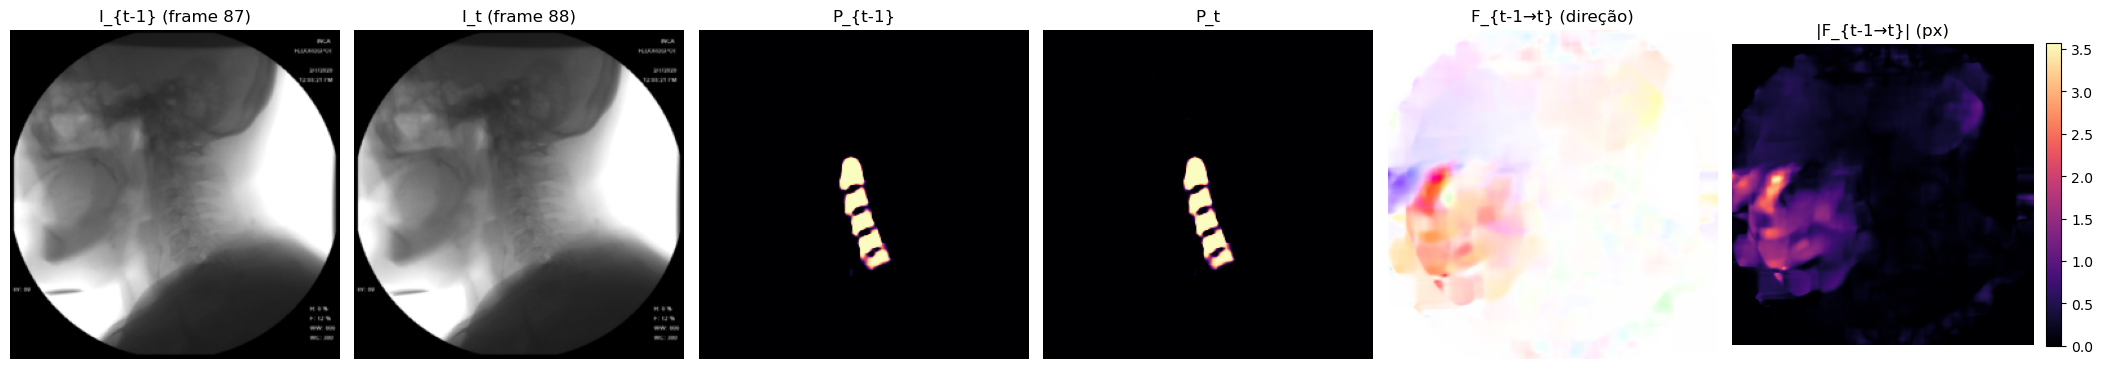

,pixels,p50 (px),p95 (px),máx (px)
região,,,,
imagem inteira,65536,0.10,1.12,3.57
dentro de P_{t-1},1260,0.07,0.18,0.28


In [6]:
preds = predict_pair(SELECTION)
RESULT = transport_pair(SELECTION, preds, FLOW_METHOD, FLOW_PREPROCESS, PHOTO_NORM, WARP_CONVENTION, ALPHA)

print(f"{SELECTION} | {RESULT['config']}")
magnitude = np.linalg.norm(RESULT["F_used"], axis=0)
flow_rgb = flow_to_image(torch.from_numpy(RESULT["F_used"])).permute(1, 2, 0).numpy()

fig, axes = plt.subplots(1, 6, figsize=(21, 3.9))
panels = [
    (RESULT["I_prev"], f"I_{{t-1}} (frame {SELECTION['frame_prev']})", "gray"),
    (RESULT["I_t"], f"I_t (frame {SELECTION['frame_t']})", "gray"),
    (RESULT["P_prev"], "P_{t-1}", "magma"),
    (RESULT["P_t"], "P_t", "magma"),
]
for ax, (image, title, cmap) in zip(axes, panels):
    ax.imshow(image, cmap=cmap, vmin=0, vmax=1)
    ax.set_title(title)
axes[4].imshow(flow_rgb)
axes[4].set_title(f"{RESULT['flow_name']} (direção)")
mappable = axes[5].imshow(magnitude, cmap="magma")
axes[5].set_title(f"|{RESULT['flow_name']}| (px)")
fig.colorbar(mappable, ax=axes[5], fraction=0.046, pad=0.04)
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

display(magnitude_table(RESULT, MASK_THRESH).round(2))

## 6. Imagens sobrepostas

Com `I_{t-1}` original, o fantasma mostra o movimento bruto entre os frames. Com `W(I_{t-1})`, uma
imagem nítida indica que o flow explicou o movimento. A opacidade é a da camada de cima, sobre $I_t$.

In [7]:
IMAGE_SOURCES = {"W(I_{t-1}) transportada": "I_warped", "I_{t-1} original": "I_prev"}


def render_images(opacity, source):
    top = RESULT[IMAGE_SOURCES[source]]
    blend = (1.0 - opacity) * RESULT["I_t"] + opacity * top
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(blend, cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"{source} sobre I_t (opacidade {opacity:.2f})")
    ax.axis("off")
    plt.show()


if HAS_WIDGETS:
    image_controls = dict(
        opacity=widgets.FloatSlider(min=0, max=1, step=0.01, value=OPACITY, description="Opacidade"),
        source=widgets.Dropdown(options=list(IMAGE_SOURCES), description="Camada"),
    )
    display(widgets.HBox(list(image_controls.values())), widgets.interactive_output(render_images, image_controls))
else:
    render_images(OPACITY, list(IMAGE_SOURCES)[0])

Output()

## 7. Máscaras sobrepostas

Máscaras binarizadas no limiar escolhido, sobre $I_t$, com preenchimento na opacidade do controle e
contorno sempre opaco. Um bom transporte deixa $\tilde P_{t-1\to t}$ mais próxima de $P_t$ do que
$P_{t-1}$ estava.

In [8]:
MASK_LAYERS = {"P_{t-1}": ("P_prev", "#56B4E9"), "P̃_{t-1→t}": ("P_tilde", "#E69F00"), "P_t": ("P_t", "#009E73")}


def render_masks(opacity, thresh, show_prev, show_tilde, show_t):
    visible = dict(zip(MASK_LAYERS, (show_prev, show_tilde, show_t)))
    rgb = np.repeat(RESULT["I_t"][..., None], 3, axis=-1).copy()
    fig, ax = plt.subplots(figsize=(6, 6))
    outlines = []
    for name, (key, color) in MASK_LAYERS.items():
        if not visible[name]:
            continue
        mask = RESULT[key] >= thresh
        rgb[mask] = (1.0 - opacity) * rgb[mask] + opacity * np.array(plt.matplotlib.colors.to_rgb(color))
        outlines.append((mask, color))
    ax.imshow(rgb, vmin=0, vmax=1)
    for mask, color in outlines:
        if mask.any() and not mask.all():
            ax.contour(mask, levels=[0.5], colors=[color], linewidths=1.5)
    handles = [Patch(color=MASK_LAYERS[name][1], label=name) for name, shown in visible.items() if shown]
    if handles:
        ax.legend(handles=handles, loc="upper right", fontsize=9)
    ax.set_title(f"Máscaras sobre I_t (limiar {thresh:.2f})")
    ax.axis("off")
    plt.show()


if HAS_WIDGETS:
    mask_controls = dict(
        opacity=widgets.FloatSlider(min=0, max=1, step=0.01, value=OPACITY, description="Opacidade"),
        thresh=widgets.FloatSlider(min=0.05, max=0.95, step=0.05, value=MASK_THRESH, description="Limiar"),
        show_prev=widgets.Checkbox(value=False, description="P_{t-1}"),
        show_tilde=widgets.Checkbox(value=True, description="P̃_{t-1→t}"),
        show_t=widgets.Checkbox(value=True, description="P_t"),
    )
    display(widgets.VBox([widgets.HBox([mask_controls["opacity"], mask_controls["thresh"]]),
                          widgets.HBox([mask_controls[k] for k in ("show_prev", "show_tilde", "show_t")])]),
            widgets.interactive_output(render_masks, mask_controls))
else:
    render_masks(OPACITY, MASK_THRESH, False, True, True)

Output()

## 8. Explorador do erro de movimento

Valores baixos de $M_{noc}$ indicam pixels que o warp não explicou: oclusão, flow ruim ou mudança real
de brilho, como a chegada do contraste. O slider de $\alpha$ começa no padrão do DTC-TRUS, e $\alpha=1$
é a forma literal $\exp(-|I_t - W|)$.

In [9]:
def render_motion_error(alpha, color_range, opacity):
    I_t, I_warped = RESULT["I_t"], RESULT["I_warped"]
    difference = np.abs(I_t - I_warped)
    M_noc = motion_error(I_t, I_warped, alpha)
    vmin, vmax = color_range

    fig, axes = plt.subplots(1, 5, figsize=(19, 4.2))
    axes[0].imshow(I_t, cmap="gray", vmin=0, vmax=1)
    axes[0].set_title("I_t")
    axes[1].imshow(I_warped, cmap="gray", vmin=0, vmax=1)
    axes[1].set_title("W(I_{t-1})")
    shown = axes[2].imshow(difference, cmap="magma", vmin=0, vmax=max(np.percentile(difference, 99.5), 1e-6))
    axes[2].set_title("|I_t − W(I_{t-1})|")
    fig.colorbar(shown, ax=axes[2], fraction=0.046, pad=0.04)
    shown = axes[3].imshow(M_noc, cmap="viridis", vmin=vmin, vmax=vmax)
    axes[3].set_title(f"M_noc (α={alpha:.2f})")
    fig.colorbar(shown, ax=axes[3], fraction=0.046, pad=0.04)
    axes[4].imshow(I_t, cmap="gray", vmin=0, vmax=1)
    axes[4].imshow(M_noc, cmap="viridis", vmin=vmin, vmax=vmax, alpha=opacity)
    axes[4].set_title("M_noc sobre I_t")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()
    print(f"M_noc médio: {M_noc.mean():.3f} | fração de pixels com M_noc < 0,5: {(M_noc < 0.5).mean():.3f}")


if HAS_WIDGETS:
    error_controls = dict(
        alpha=widgets.FloatSlider(min=0, max=20, step=0.01, value=ALPHA, description="α"),
        color_range=widgets.FloatRangeSlider(min=0, max=1, step=0.01, value=(0.0, 1.0), description="Escala"),
        opacity=widgets.FloatSlider(min=0, max=1, step=0.01, value=OPACITY, description="Opacidade"),
    )
    display(widgets.HBox(list(error_controls.values())), widgets.interactive_output(render_motion_error, error_controls))
else:
    render_motion_error(ALPHA, (0.0, 1.0), OPACITY)

Output()

## 9. Métricas do par, por método

Todos os métodos no par selecionado, com o mesmo `FLOW_PREPROCESS`, `PHOTO_NORM` e `WARP_CONVENTION`,
na imagem inteira. O transporte só ajuda se Dice$(P_t, \tilde P)$ superar o baseline sem transporte e
$|I_t - W|$ ficar abaixo de $|I_t - I_{t-1}|$. As colunas contra a anotação só aparecem quando o frame
$t$ é anotado neste split. Um par isolado é anedótico: use esta tabela para orientar a exploração, não
para concluir.

In [10]:
def annotation_for(selection):
    '''Anotação booleana do frame t, ou None se ele não estiver anotado no split.'''
    ds, video_id, frame_t = datasets[selection["split"]], selection["video_id"], selection["frame_t"]
    if frame_t not in annotated_frames(selection["split"], video_id):
        return None
    sample = ds.__getitem__(video_id=video_id, frame_id=frame_t)
    return sample["segmentation"].numpy() > 0 if sample["metadata"]["is_labeled"] else None


gt = annotation_for(SELECTION)
rows = {
    method: pair_metrics(
        transport_pair(SELECTION, preds, method, FLOW_PREPROCESS, PHOTO_NORM, WARP_CONVENTION, ALPHA),
        MASK_THRESH, gt,
    )
    for method in FLOW_METHODS
}
print(f"{SELECTION} | pré-proc={FLOW_PREPROCESS}, norm={PHOTO_NORM}, warp={WARP_CONVENTION}, α={ALPHA:.2f}")
display(pd.DataFrame(rows).T.round(4))

{'split': 'test', 'video_id': 2, 'frame_prev': 87, 'frame_t': 88} | pré-proc=dtc_rgb, norm=raw, warp=dtc_trus, α=13.28


,"Dice(P_t, P̃)","Dice(P_t, P_{t-1}) sem transporte",|I_t - W| médio,|I_t - I_{t-1}| médio,L_temporal DTC-TRUS,"Dice(GT, P̃)","Dice(GT, P_t)"
farneback,0.9757,0.9745,0.0034,0.0042,0.0425,0.8254,0.8352
dis,0.9765,0.9745,0.0031,0.0042,0.0399,0.8261,0.8352
raft_small,0.9761,0.9745,0.0047,0.0042,0.0528,0.8278,0.8352
raft_large,0.9757,0.9745,0.0044,0.0042,0.0504,0.8254,0.8352
